# EDA — Wine Quality (Parte Comum)

Dataset: UCI *Wine Quality* (tinto + branco, 6 497 vinhos, 11 variáveis físico-químicas, nota `quality` 3–9 = **7 classes**).
A lógica está em `src/parte_comum/eda.py`; este notebook executa e comenta cada pilar. A coluna `tipo` (tinto/branco) é **apenas auxiliar** para análise — não entra no K-Means.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1] / "src" / "parte_comum"))  # notebooks/parte_comum -> src/parte_comum
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Image
from common import *
estilo_graficos()
pd.set_option("display.width", 200, "display.max_columns", 30)
%matplotlib inline
import eda
df = carregar_dados('ambos')
saida = pasta_saida('eda')

## 1. Estrutural

In [2]:
est = eda.estrutural(df)
display(df.head())
display(est['info'])
est['resumo']

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,tipo
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,tinto
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,tinto
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,tinto
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto


,dtype,nulos,valores_unicos,min,max
alcohol,float64,0,111,8.00000,14.90000
chlorides,float64,0,214,0.00900,0.61100
citric_acid,float64,0,89,0.00000,1.66000
density,float64,0,998,0.98711,1.03898
fixed_acidity,float64,0,106,3.80000,15.90000
free_sulfur_dioxide,float64,0,135,1.00000,289.00000
ph,float64,0,108,2.72000,4.01000
quality,int64,0,7,3.00000,9.00000
residual_sugar,float64,0,316,0.60000,65.80000
sulphates,float64,0,111,0.22000,2.00000


{'linhas': 6497,
 'colunas': 13,
 'nulos_total': 0,
 'duplicatas': 1177,
 'duplicatas_pct': np.float64(18.12),
 'n_classes': 7,
 'classes': [3, 4, 5, 6, 7, 8, 9],
 'free_so2_maior_que_total': 0,
 'por_tipo': {'branco': 4898, 'tinto': 1599}}

**Leitura.** 6 497 linhas × 13 colunas (11 numéricas contínuas, `quality` inteira/ordinal, `tipo` categórica). Sem valores nulos. Há **1 177 linhas duplicadas (18,1 %)**: com apenas 11 medidas de precisão limitada é plausível que vinhos distintos tenham a mesma ficha, então foram **mantidas** (a remoção apagaria quase só vinhos 'comuns', reforçando o desbalanceamento). Consistência física: nenhuma amostra com SO₂ livre > SO₂ total.

## 2. Distribucional

In [3]:
dist = eda.distribucional(df)
display(dist['descritiva'].round(3))
display(dist['classes'])
display(dist['classes_por_tipo'])

,count,mean,std,min,25%,50%,75%,max,assimetria,curtose,p_normalidade
fixed_acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900,1.723,5.061,0.0
volatile_acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580,1.495,2.825,0.0
citric_acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660,0.472,2.397,0.0
residual_sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800,1.435,4.359,0.0
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611,5.400,50.898,0.0
free_sulfur_dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000,1.220,7.906,0.0
total_sulfur_dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000,-0.001,-0.372,0.0
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039,0.504,6.606,0.0
ph,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010,0.387,0.368,0.0
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000,1.797,8.654,0.0


,n,pct
quality,,
3,30,0.46
4,216,3.32
5,2138,32.91
6,2836,43.65
7,1079,16.61
8,193,2.97
9,5,0.08


tipo,branco,tinto
quality,,
3,20,10
4,163,53
5,1457,681
6,2198,638
7,880,199
8,175,18
9,5,0


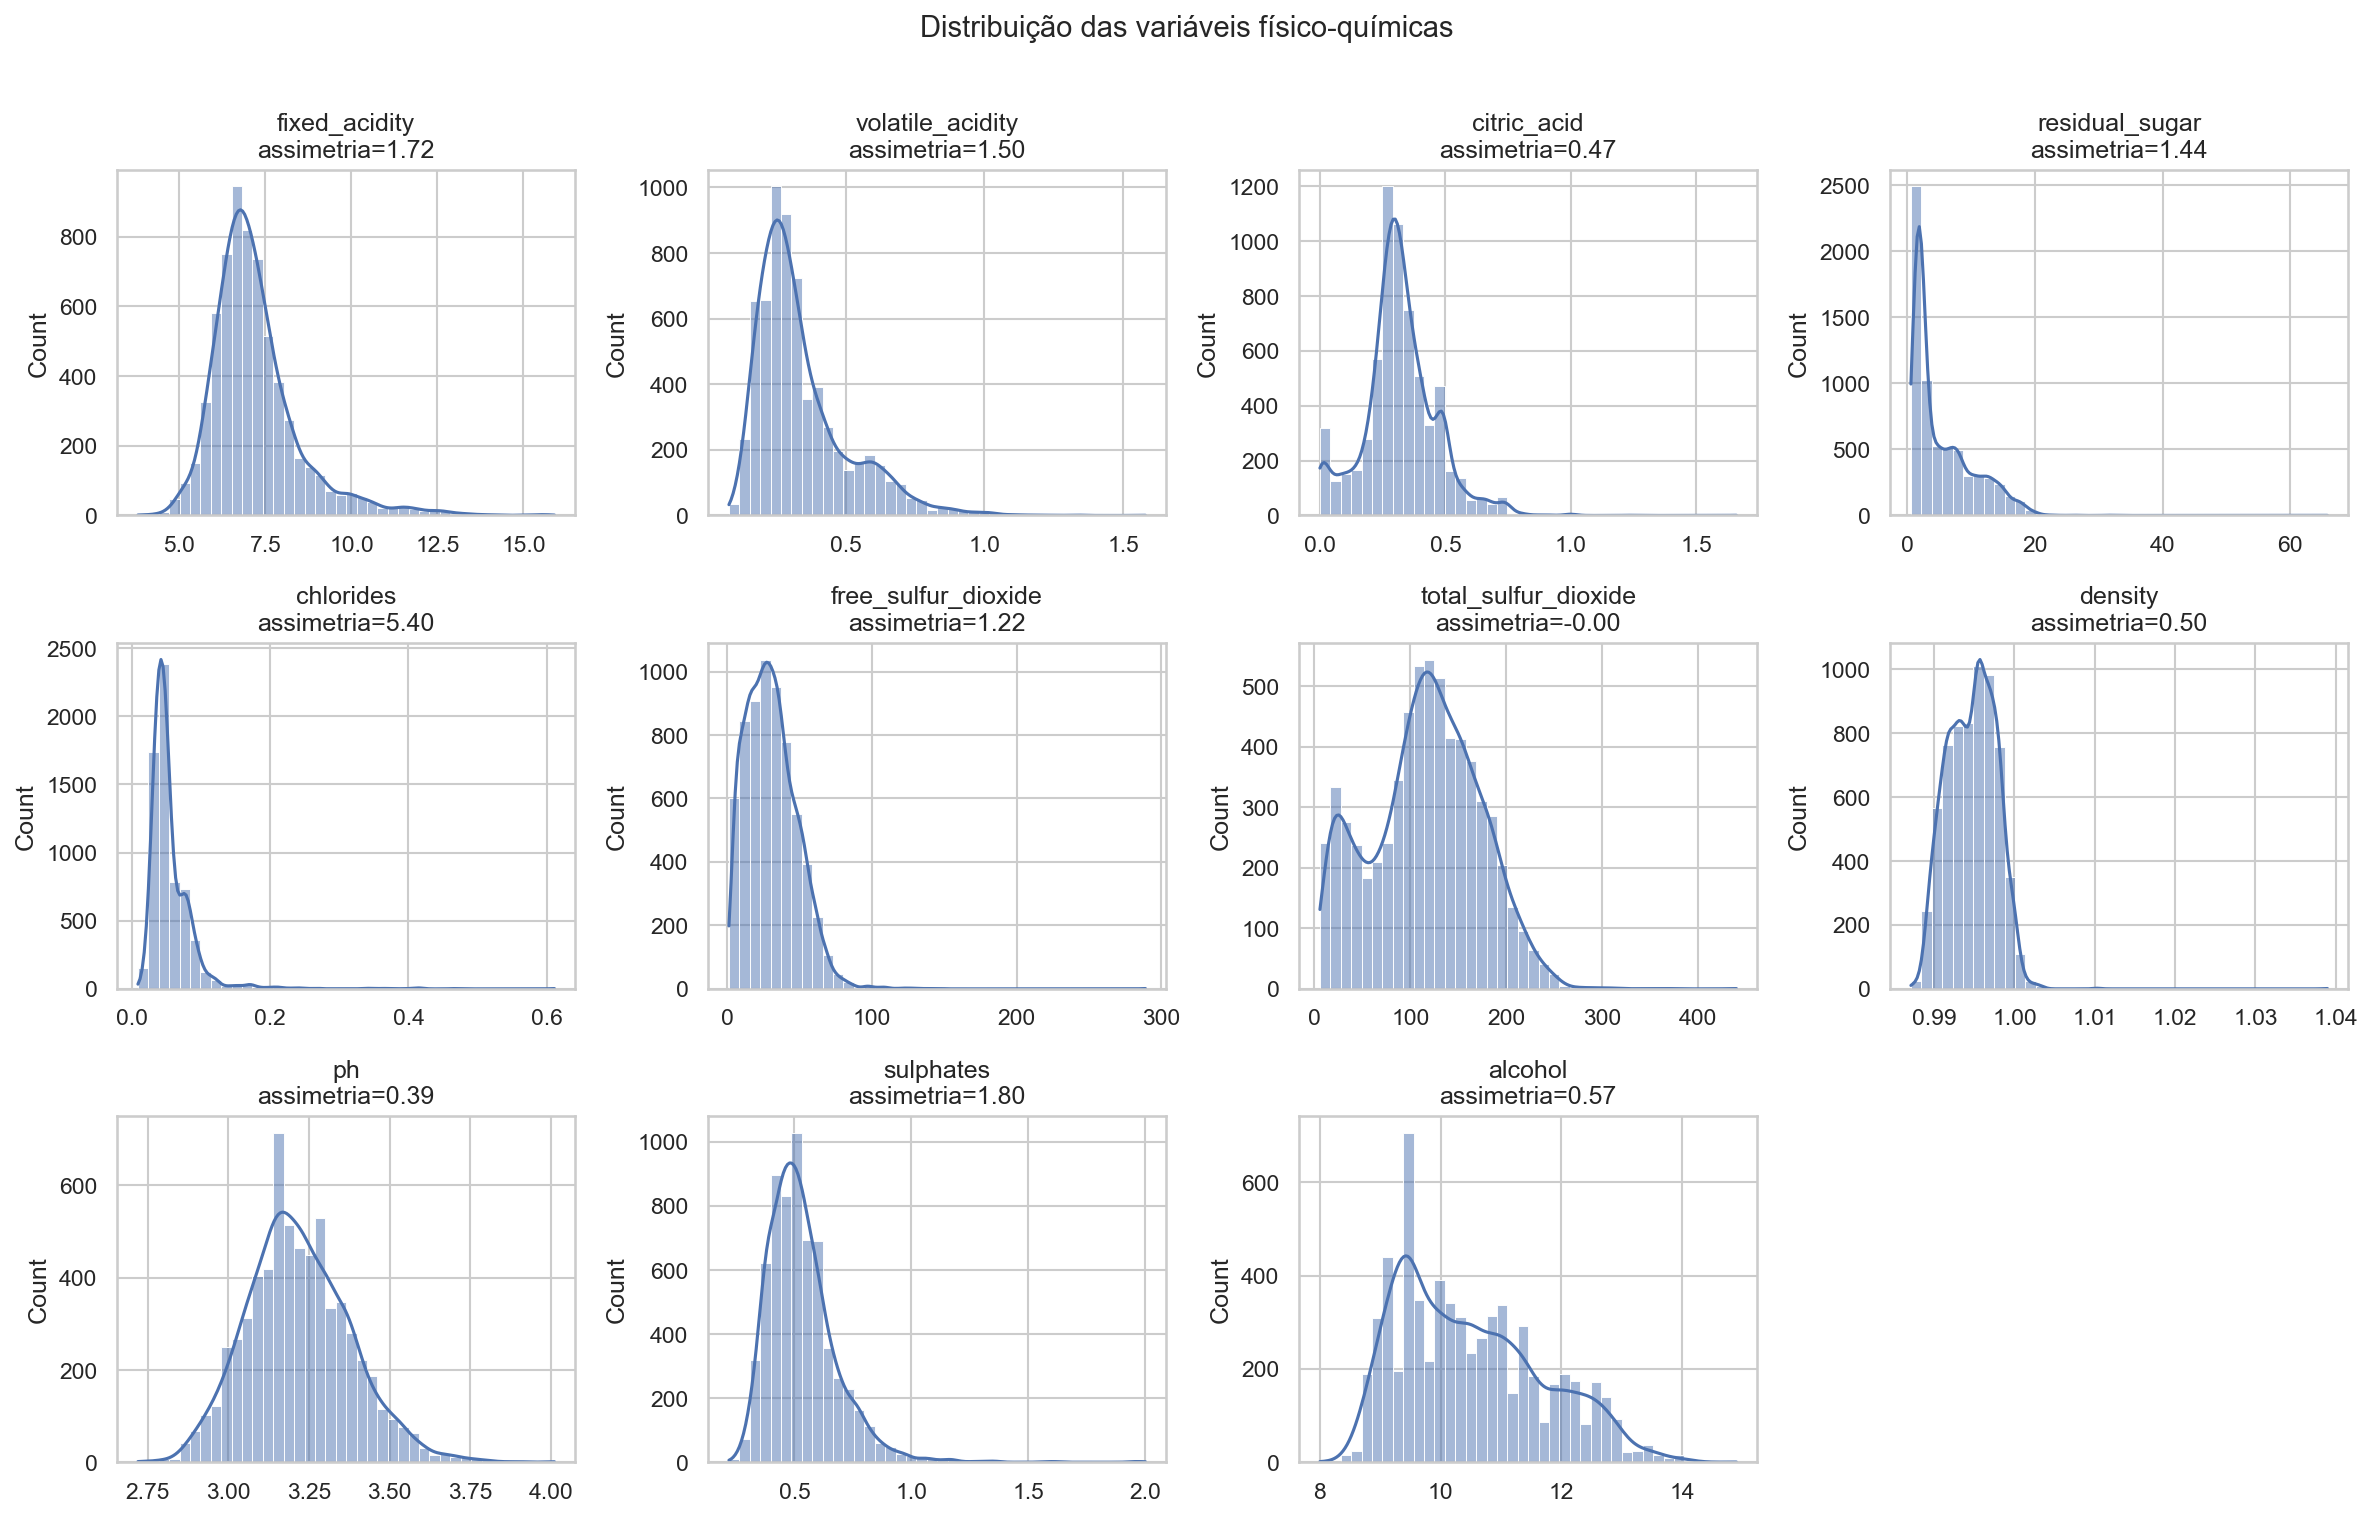

In [4]:
display(Image(filename=str(OUT_DIR / "eda/dist_histogramas.png")))

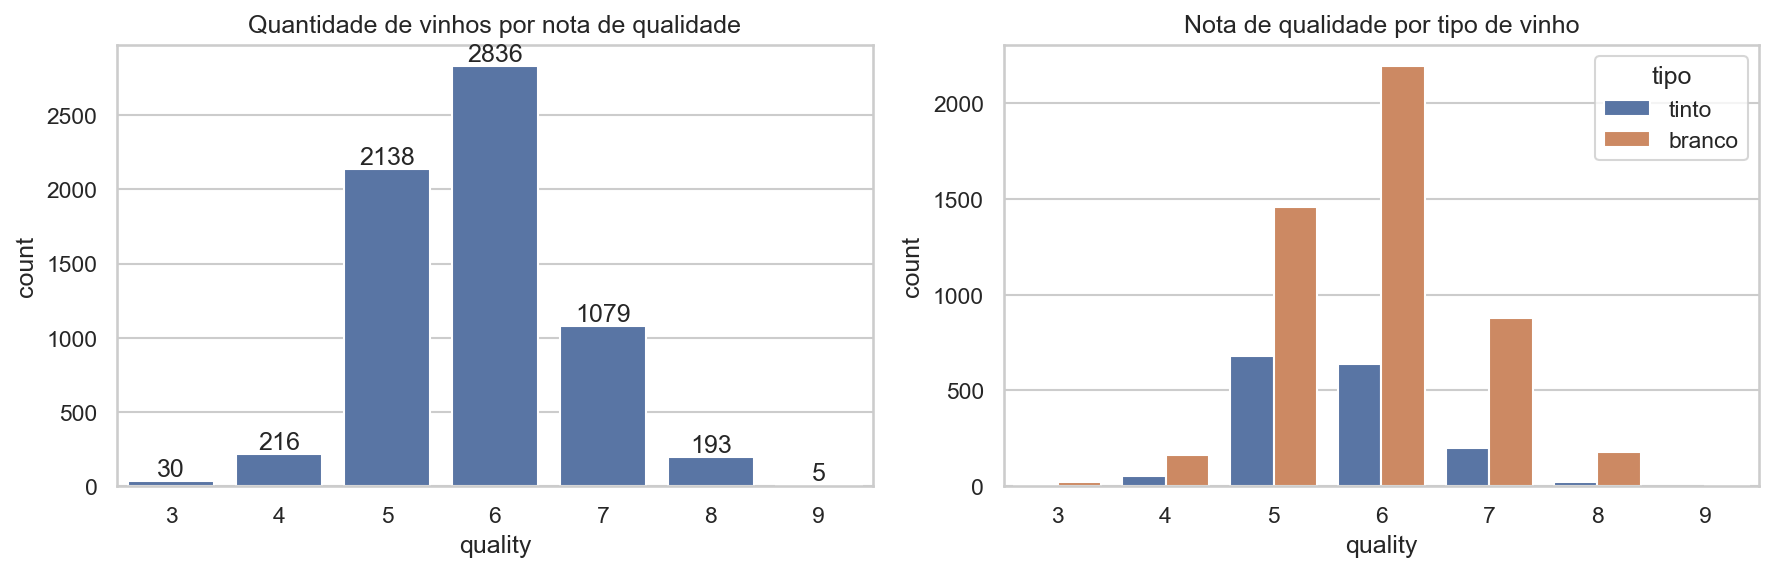

In [5]:
display(Image(filename=str(OUT_DIR / "eda/dist_classes.png")))

**Leitura.** Quase todas as variáveis são assimétricas à direita (cloretos: assimetria 5,4; sulfatos 1,8; acidez fixa 1,7) e **nenhuma passa no teste de normalidade** (p < 0,05 com n grande). As classes são **muito desbalanceadas**: 5 e 6 somam 76,6 %; as notas 3 (30), 8 (193) e 9 (5 vinhos) são raríssimas. A nota 9 só existe no vinho branco.

## 3. Relacional

In [6]:
rel = eda.relacional(df)
display(rel['com_classe'].round(3))
display(rel['kruskal'].round(4))
display(rel['pares'].head(8).round(3))
display(rel['sep_tipo'].round(2))

,spearman_com_quality,pearson_com_quality
alcohol,0.447,0.444
density,-0.323,-0.306
chlorides,-0.295,-0.201
volatile_acidity,-0.258,-0.266
citric_acid,0.106,0.086
fixed_acidity,-0.098,-0.077
free_sulfur_dioxide,0.087,0.055
total_sulfur_dioxide,-0.055,-0.041
ph,0.033,0.020
sulphates,0.030,0.038


,H,p_valor
variavel,,
fixed_acidity,70.9944,0.0000
volatile_acidity,476.7652,0.0000
citric_acid,78.3832,0.0000
residual_sugar,39.1751,0.0000
chlorides,607.7882,0.0000
free_sulfur_dioxide,125.8789,0.0000
total_sulfur_dioxide,53.9036,0.0000
density,758.8906,0.0000
ph,15.2735,0.0182


,var_a,var_b,pearson,spearman
40,free_sulfur_dioxide,total_sulfur_dioxide,0.721,0.741
51,density,alcohol,-0.687,-0.699
30,residual_sugar,density,0.553,0.527
29,residual_sugar,total_sulfur_dioxide,0.495,0.455
6,fixed_acidity,density,0.459,0.434
14,volatile_acidity,total_sulfur_dioxide,-0.414,-0.344
28,residual_sugar,free_sulfur_dioxide,0.403,0.388
38,chlorides,sulphates,0.396,0.370


,diferenca_padronizada
total_sulfur_dioxide,1.63
volatile_acidity,-1.52
chlorides,-1.19
sulphates,-1.13
fixed_acidity,-1.13
free_sulfur_dioxide,1.09
density,-0.91
residual_sugar,0.81
ph,-0.76
citric_acid,0.44


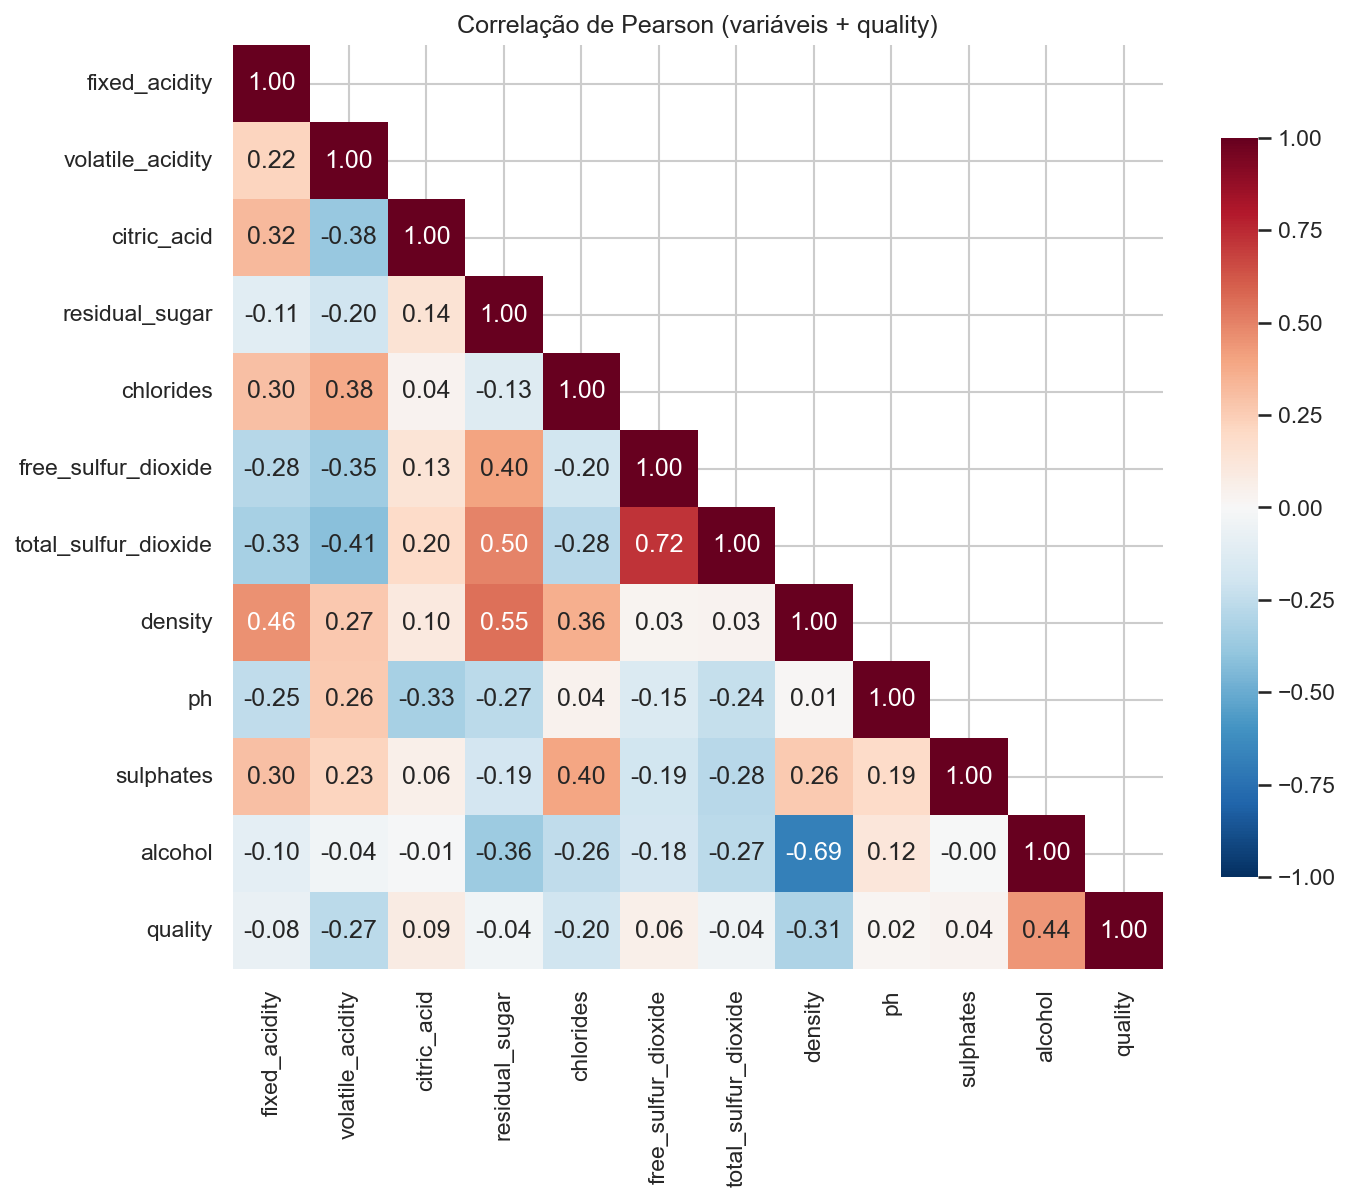

In [7]:
display(Image(filename=str(OUT_DIR / "eda/corr_pearson.png")))

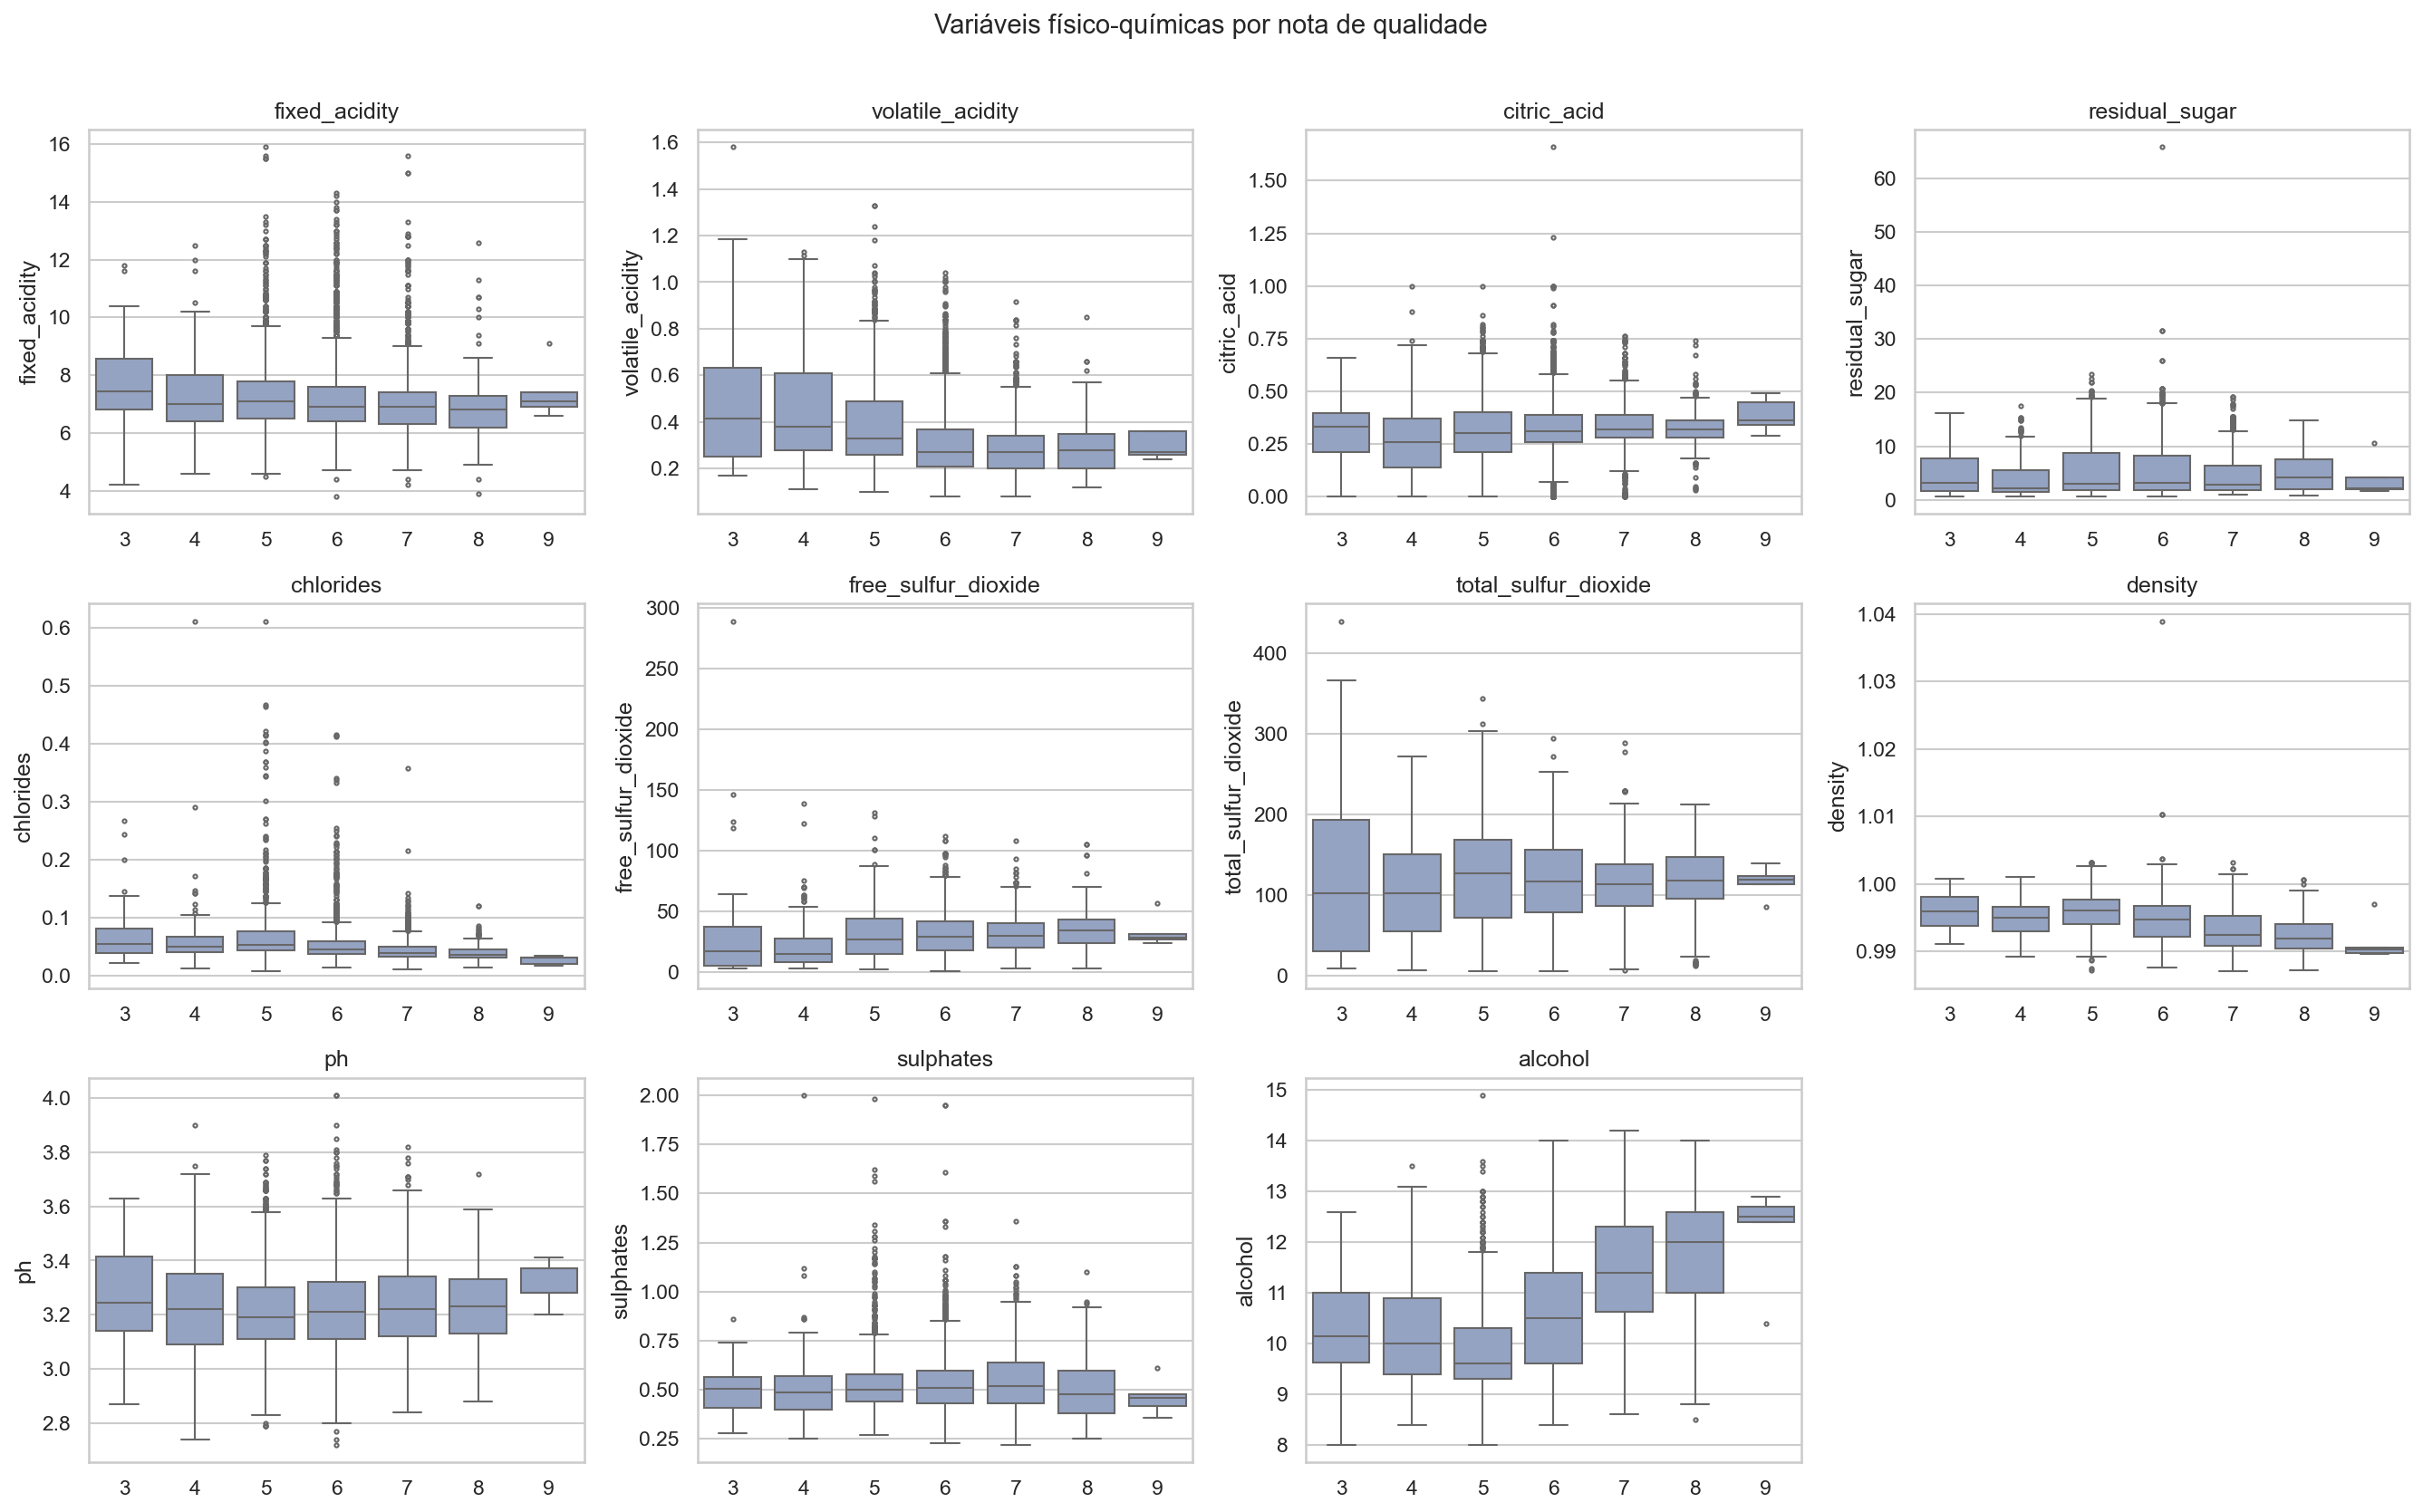

In [8]:
display(Image(filename=str(OUT_DIR / "eda/rel_boxplots_por_classe.png")))

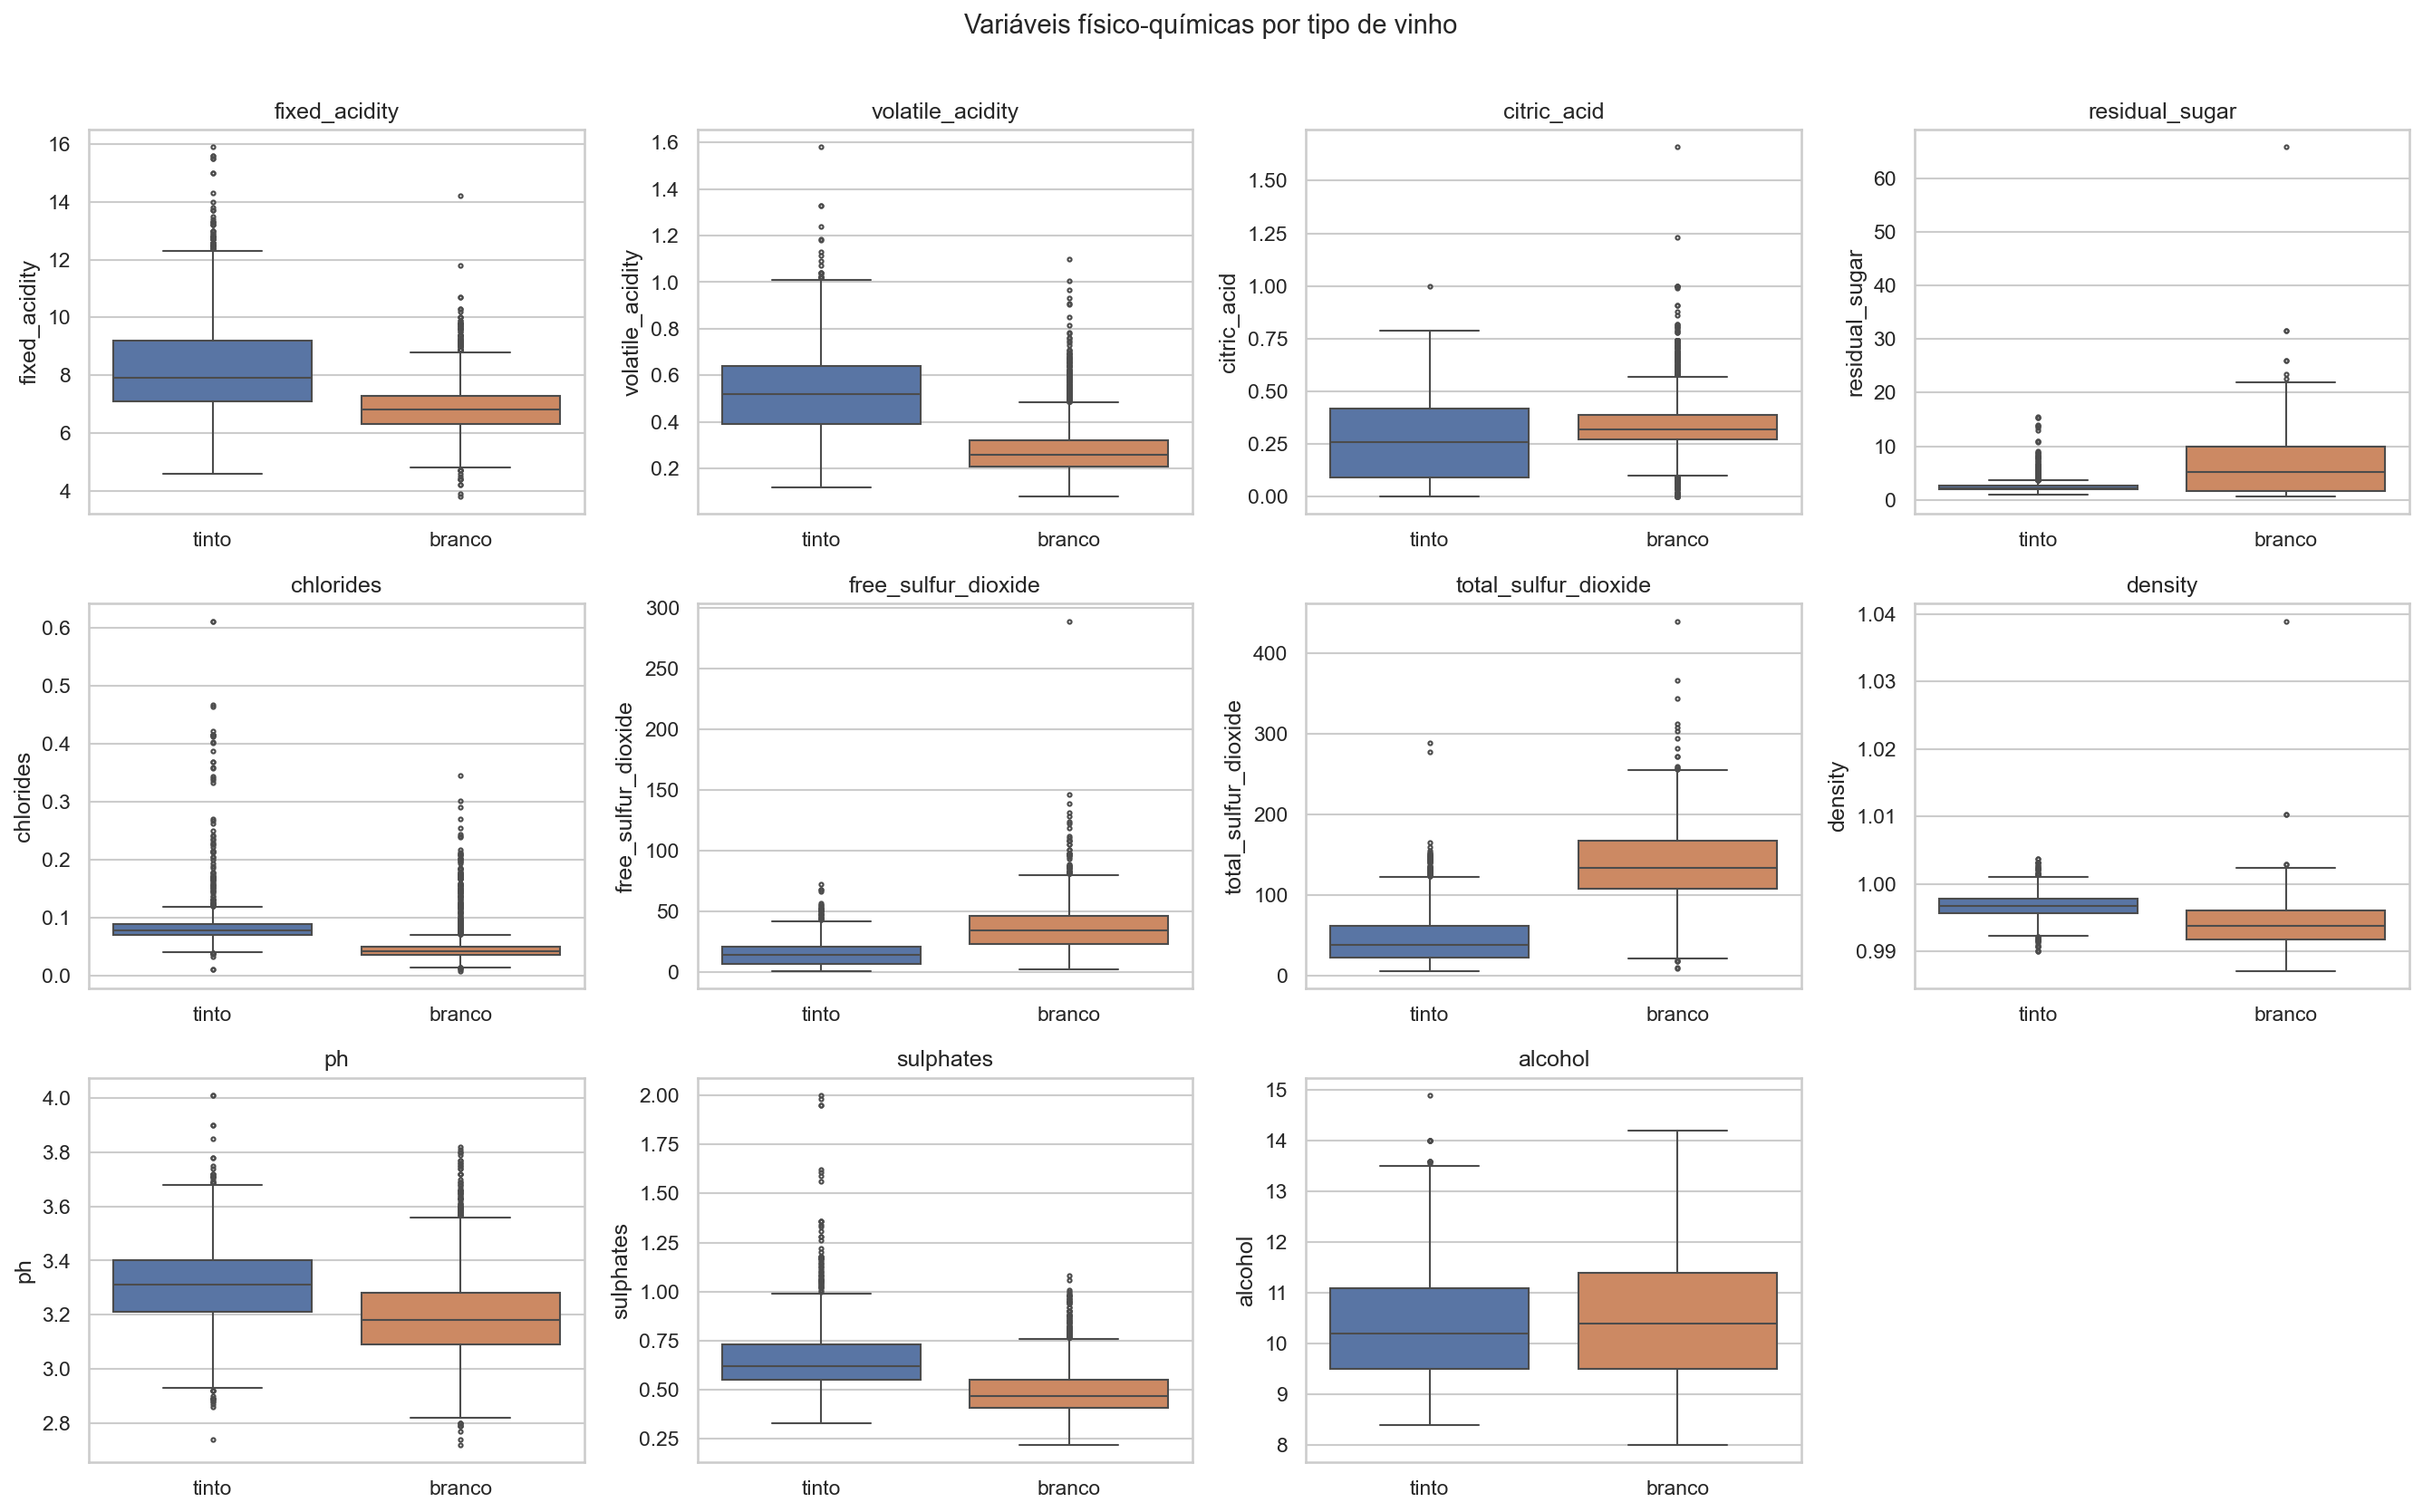

In [9]:
display(Image(filename=str(OUT_DIR / "eda/rel_boxplots_por_tipo.png")))

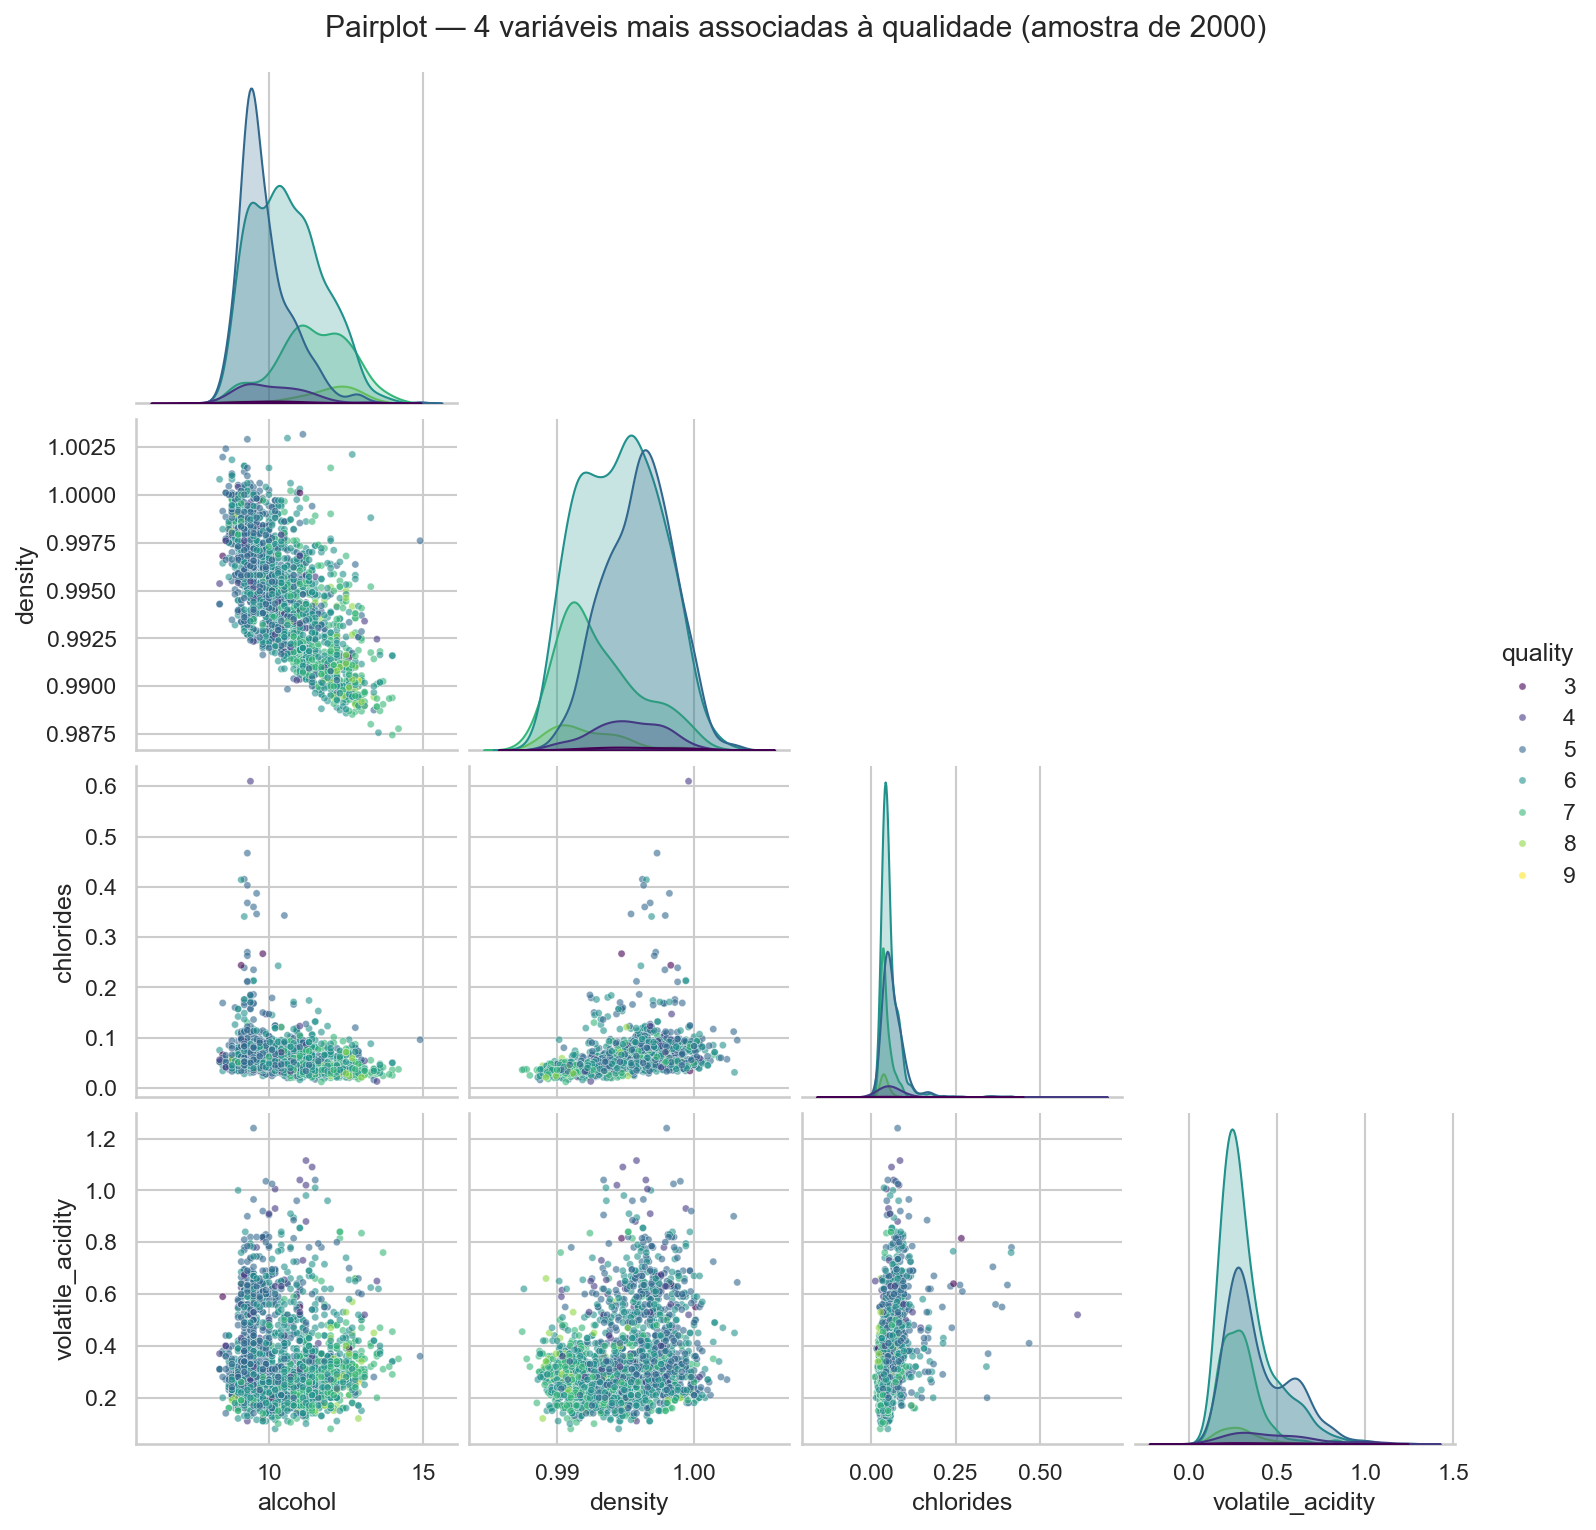

In [10]:
display(Image(filename=str(OUT_DIR / "eda/rel_pairplot_top4.png")))

**Leitura.**
- Com a classe: `alcohol` é a variável mais associada (ρ = +0,45); depois `density` (−0,32), `chlorides` (−0,30) e `volatile_acidity` (−0,26). Nenhuma passa de |0,45|: **a qualidade é só fracamente explicada por cada variável isoladamente**.
- Entre variáveis: SO₂ livre × total (0,72), densidade × álcool (−0,69), açúcar × densidade (0,55) — há redundância/multicolinearidade.
- As variáveis separam **tinto de branco** muito mais do que separam notas de qualidade (diferença padronizada de até 1,6 desvio em SO₂ total). Isso antecipa que o K-Means, não supervisionado, tenderá a agrupar por tipo de vinho.

## 4. Outliers

In [11]:
out = eda.outliers(df)
display(out['tabela'])
display(out['por_classe'])
display(out['extremos'])
print(f"Linhas com >=1 outlier (IQR): {out['n_linhas_com_outlier_iqr']} ({out['pct_linhas_com_outlier_iqr']}%)")

,limite_inf_iqr,limite_sup_iqr,n_outliers_iqr,pct_iqr,n_outliers_z3,pct_z3,max_|z|
fixed_acidity,4.450000,9.650000,357,5.49,128,1.97,6.7
volatile_acidity,-0.025000,0.655000,377,5.80,95,1.46,7.5
citric_acid,0.040000,0.600000,509,7.83,28,0.43,9.2
residual_sugar,-7.650000,17.550000,118,1.82,26,0.40,12.7
chlorides,-0.002500,0.105500,286,4.40,107,1.65,15.8
free_sulfur_dioxide,-19.000000,77.000000,62,0.95,36,0.55,14.6
total_sulfur_dioxide,-41.500000,274.500000,10,0.15,8,0.12,5.7
density,0.985365,1.003965,3,0.05,3,0.05,14.8
ph,2.795000,3.635000,73,1.12,33,0.51,4.9
sulphates,0.175000,0.855000,191,2.94,75,1.15,9.9


,n_vinhos,com_algum_outlier_iqr,pct
quality,,,
3,30,19,63.3
4,216,79,36.6
5,2138,622,29.1
6,2836,574,20.2
7,1079,154,14.3
8,193,25,13.0
9,5,0,0.0


,linha,variavel,|z|,valor
0,258,chlorides,15.840967,0.61100
1,151,chlorides,15.812423,0.61000
2,4380,density,14.767654,1.03898
3,6344,free_sulfur_dioxide,14.562446,289.00000
4,4380,residual_sugar,12.685846,65.80000
5,106,chlorides,11.730628,0.46700
6,81,chlorides,11.644996,0.46400
7,692,chlorides,10.446147,0.42200
8,1370,chlorides,10.246338,0.41500
9,754,chlorides,10.246338,0.41500


Linhas com >=1 outlier (IQR): 1473 (22.7%)


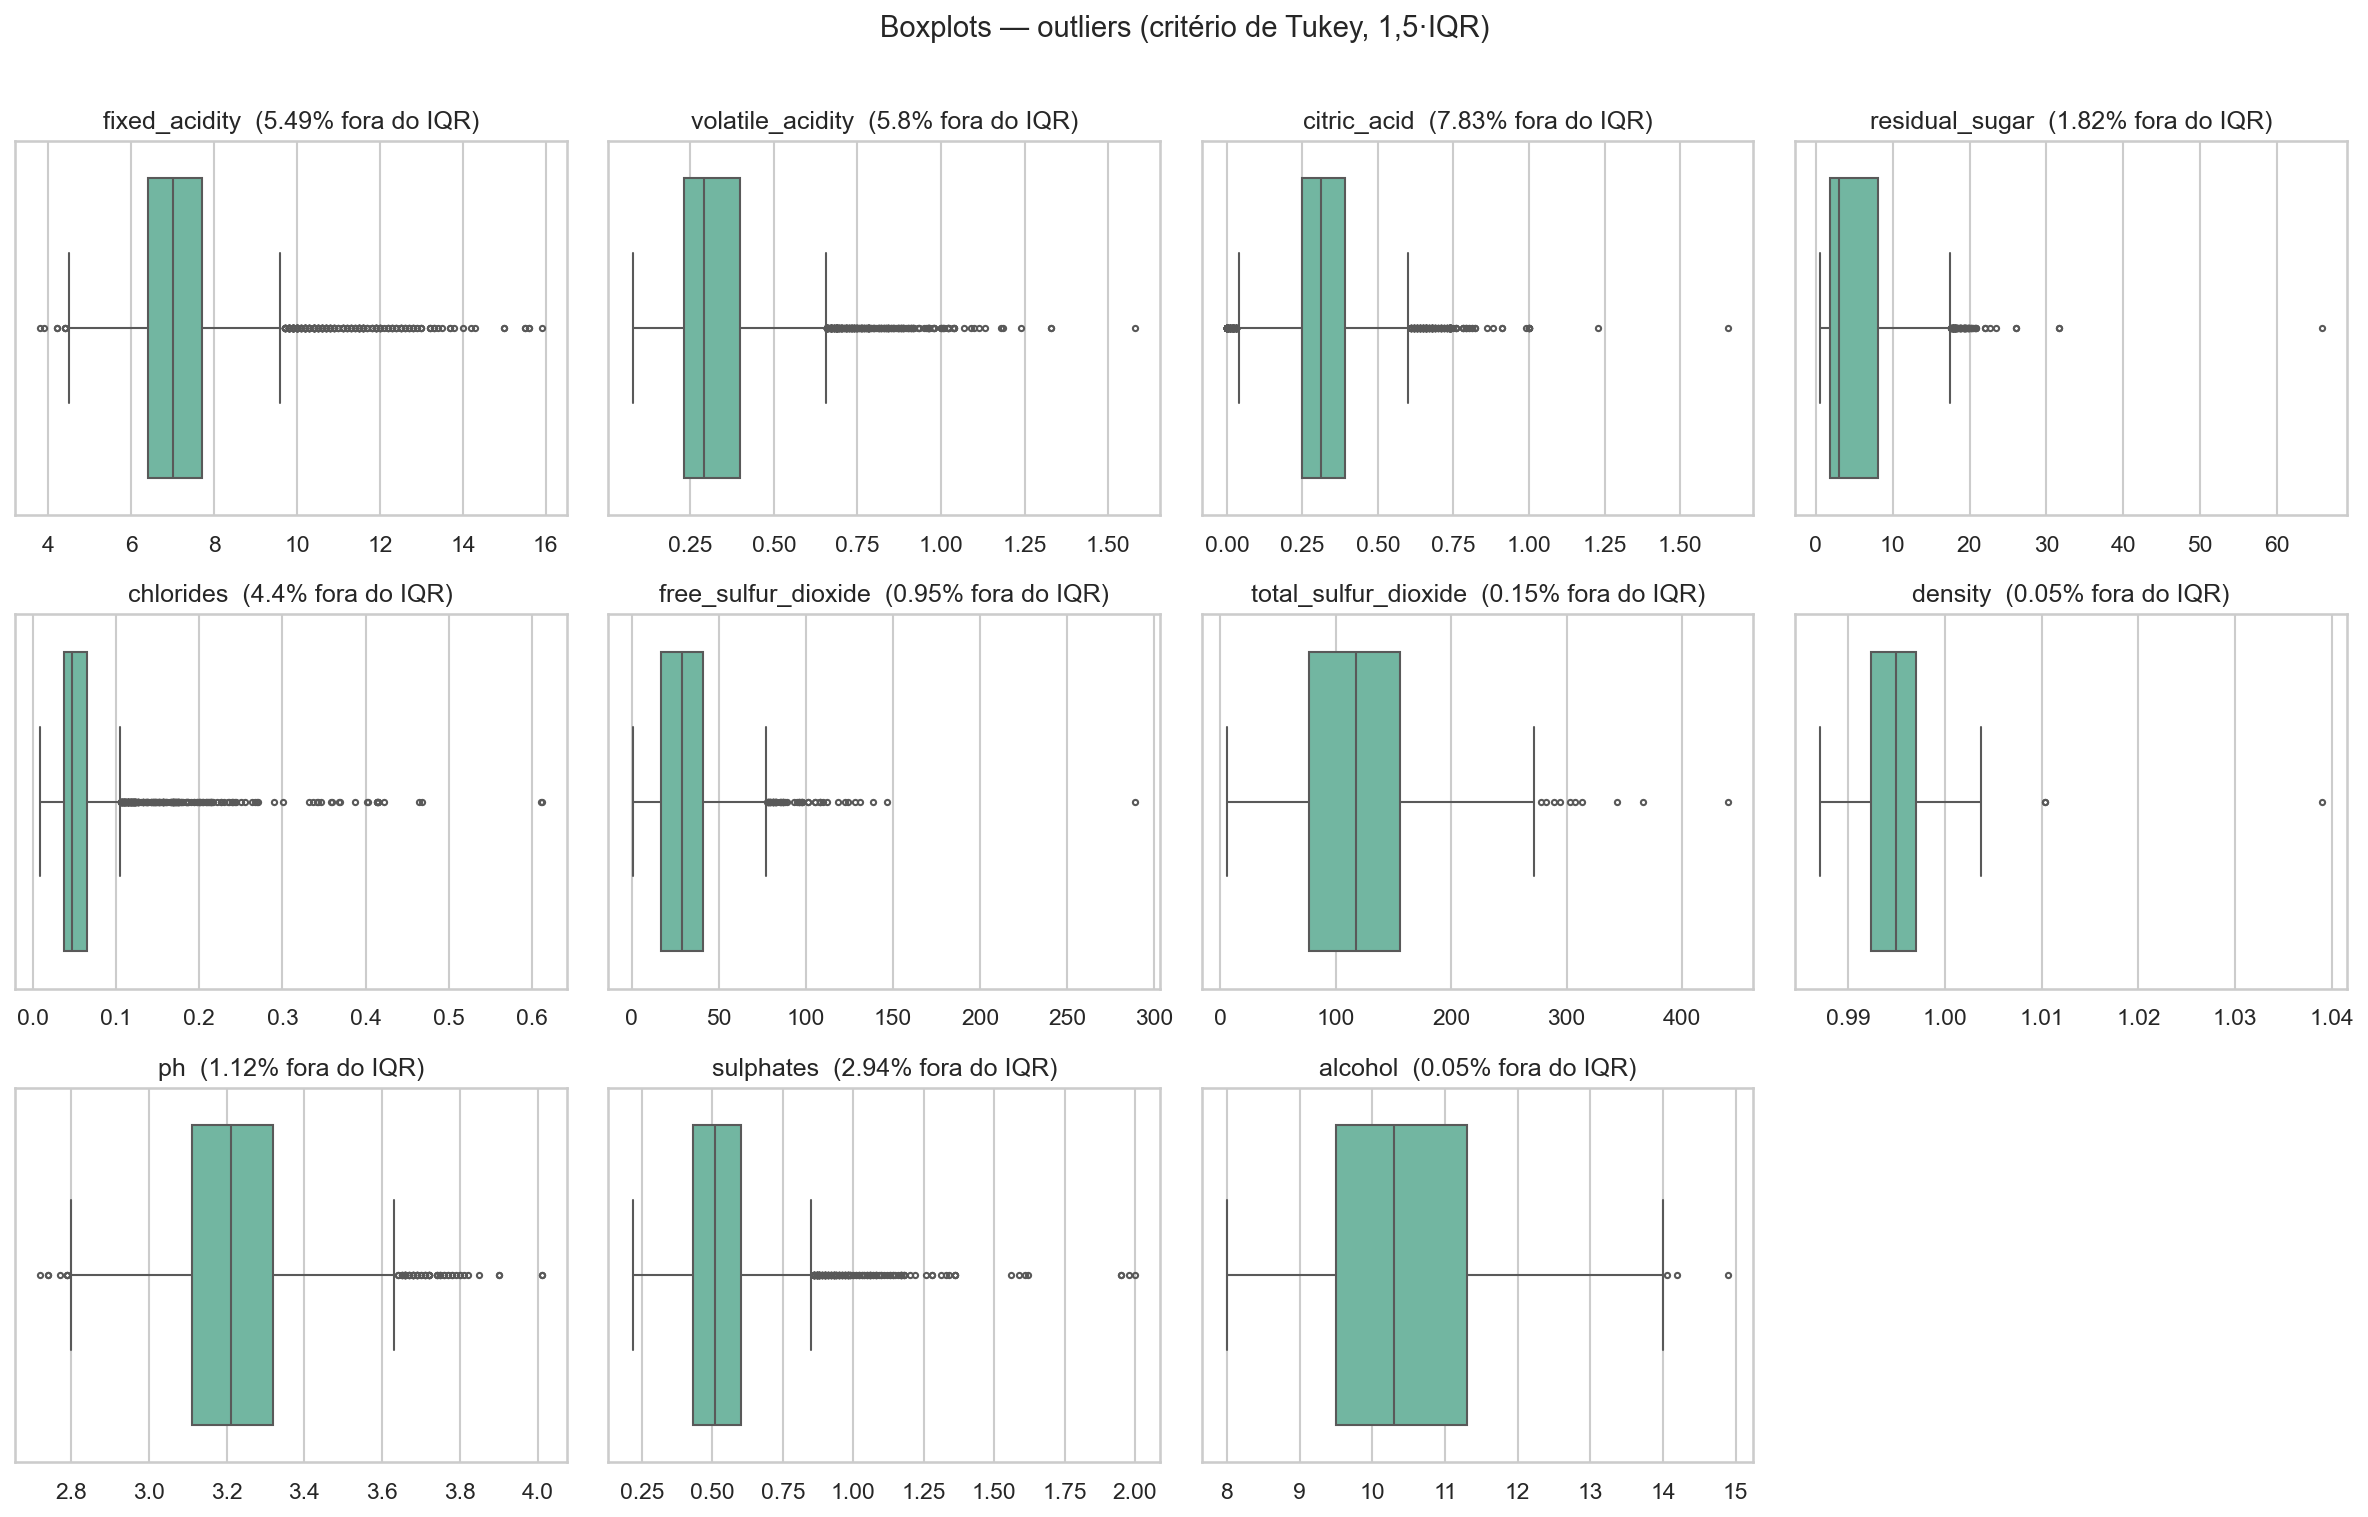

In [12]:
display(Image(filename=str(OUT_DIR / "eda/outliers_boxplots.png")))

**Discussão e decisão: não remover outliers.**
1. Há outliers em todas as variáveis, e **22,7 % das linhas** têm ao menos um (critério de Tukey) — removê-los descartaria quase um quarto dos dados.
2. Eles **se concentram nas classes raras** (63 % dos vinhos nota 3 e 37 % da nota 4 têm algum outlier, contra 13–14 % das notas 7–8): apagá-los eliminaria justamente as classes que se quer estudar.
3. A maioria é **quimicamente plausível** (cauda longa em cloretos/sulfatos/açúcar, típica de variáveis positivas assimétricas). Só 3 linhas têm ≥3 outliers extremos simultâneos (z > 3) — a mais crítica, linha 4380 (açúcar 65,8 g/L, densidade 1,039), parece vinho doce muito atípico, não erro comprovado.
4. **Mitigação:** em vez de excluir, fizemos *análise de sensibilidade* com winsorização 1–99 % antes do K-Means (ver `kmeans_metricas.ipynb`): os resultados praticamente não mudam. Registramos, porém, que o K-Means dedica um cluster inteiro (33 vinhos) a esses extremos.